# 04 · Evaluasi & analisis (Test dilihat sekali)
Tidak ada keputusan yang diambil dari notebook ini.

In [1]:
import sys; sys.path.insert(0, "../src")
import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import t3
from t3 import CFG, OUT, PRICE, SEED
from eval_utils import *

X = pd.read_parquet(OUT / "features.parquet")
blocks = json.loads((OUT / "blocks.json").read_text())
tr, te = X[X.split == "train"], X[X.split == "test"]
S = joblib.load(OUT / "tuned_all.joblib"); R, D = S["R"], S["D"]
te = te.join(S["Zd"])                                  # kolom pc* untuk eksperimen urutan agregasi
sel = json.loads((OUT / "selection.json").read_text())
fin = {f["model"]: (f["set"], f["fusion"]) for f in sel["final"]}
bm = sel["best_model"]; bs, bf = fin[bm]
y, z = te.target, np.zeros(len(te))

def ev(models, Z=te):
    df = pd.DataFrame([evaluate(y, m.predict(Z)) for m in models])
    return {**df.mean().to_dict(), "RMSE_std": df.RMSE.std(ddof=0), "collapse": is_collapsed(t3.predict(models, Z), y)}

## Tabel utama (Test)

In [2]:
rows, P = [], {}
for m, (s, f) in fin.items():
    cells = {"A default": [D[(m, "A")]], "B default": [D[(m, "B")]], "C* default (early)": [D[(m, s)]],
             "A tuned": R[(m, "A", "early")]["models"], "B tuned": R[(m, "B", "early")]["models"], "C* tuned": R[(m, s, f)]["models"]}
    for lab, mods in cells.items():
        rows.append({"model": m, "cell": lab, "C*": f"{s}/{f}", **ev(mods)}); P[(m, lab)] = t3.predict(mods, te)
main = pd.DataFrame(rows)
naive = pd.DataFrame({k: evaluate(y, p) for k, p in {"Prediksi 0": z, "Return kemarin": te.ret}.items()}).T
print("Mayoritas DirAcc Test:", {k: round(v, 3) for k, v in majority_baselines(y).items()})
display(naive.round(6)); display(main.round(6))
main.to_csv(OUT / "test_main.csv", index=False)

Mayoritas DirAcc Test: {'Selalu naik': 0.591, 'Selalu turun': 0.409, 'Mayoritas': 0.591}


,MAE,MSE,RMSE,DirAcc,PredStd
Prediksi 0,0.002205,0.000008,0.002908,0.000000,0.000000
Return kemarin,0.003084,0.000016,0.003977,0.545455,0.002887


,model,cell,C*,MAE,MSE,RMSE,DirAcc,PredStd,RMSE_std,collapse
0,GradientBoosting,A default,bge_small/early,0.002332,0.000009,0.003057,0.545455,0.000995,0.0,False
1,GradientBoosting,B default,bge_small/early,0.002323,0.000010,0.003106,0.551136,0.001094,0.0,False
2,GradientBoosting,C* default (early),bge_small/early,0.002331,0.000009,0.003041,0.517045,0.000882,0.0,False
3,GradientBoosting,A tuned,bge_small/early,0.002234,0.000009,0.002956,0.556818,0.000532,0.0,False
4,GradientBoosting,B tuned,bge_small/early,0.002199,0.000009,0.002947,0.556818,0.000606,0.0,False
5,GradientBoosting,C* tuned,bge_small/early,0.002169,0.000008,0.002896,0.579545,0.000217,0.0,False
6,Ridge,A default,bge_base/early,0.002190,0.000008,0.002890,0.534091,0.000527,0.0,False
7,Ridge,B default,bge_base/early,0.002166,0.000008,0.002885,0.585227,0.000650,0.0,False
8,Ridge,C* default (early),bge_base/early,0.002230,0.000009,0.002916,0.539773,0.000576,0.0,False
9,Ridge,A tuned,bge_base/early,0.002181,0.000008,0.002893,0.590909,0.000006,0.0,True


## Uji signifikansi
DM < 0: model pertama lebih akurat. CI = block bootstrap untuk RMSE(pertama) − RMSE(kedua).

In [3]:
rows = []
for m in fin:
    a, b, c = (P[(m, k)] for k in ("A tuned", "B tuned", "C* tuned"))
    for n, (p1, p2) in {"A vs B": (a, b), "B vs C*": (b, c), "A vs C*": (a, c), "A vs Prediksi 0": (a, z), "C* vs Prediksi 0": (c, z)}.items():
        dm, p = dm_test(y, p1, p2)
        lo, hi = block_bootstrap_ci(y, p1, "RMSE", ref_pred=p2)
        rows.append({"model": m, "pasangan": n, "DM": dm, "p": p, "dRMSE_lo": lo, "dRMSE_hi": hi})
sig = pd.DataFrame(rows); sig.to_csv(OUT / "test_significance.csv", index=False); sig.round(4)

,model,pasangan,DM,p,dRMSE_lo,dRMSE_hi
0,GradientBoosting,A vs B,0.2897,0.7724,-0.0001,0.0001
1,GradientBoosting,B vs C*,1.1947,0.2338,-0.0000,0.0001
2,GradientBoosting,A vs C*,1.7998,0.0736,0.0000,0.0001
3,GradientBoosting,A vs Prediksi 0,1.1299,0.2601,-0.0000,0.0001
4,GradientBoosting,C* vs Prediksi 0,-0.6017,0.5481,-0.0000,0.0000
5,Ridge,A vs B,0.8325,0.4063,-0.0000,0.0000
6,Ridge,B vs C*,0.3895,0.6974,-0.0000,0.0001
7,Ridge,A vs C*,0.4034,0.6872,-0.0000,0.0001
8,Ridge,A vs Prediksi 0,-1.1957,0.2334,-0.0000,0.0000
9,Ridge,C* vs Prediksi 0,-0.8739,0.3834,-0.0001,0.0000


## Ablasi blok, kontrol negatif, urutan agregasi (Test)

In [4]:
def tab(d):
    return pd.DataFrame({k: {"cv_rmse": r["cv_mse"] ** .5, **{a: b for a, b in ev(r["models"]).items() if a in ("RMSE", "MAE", "DirAcc", "PredStd")}} for k, r in d.items()}).T
display(tab(S["abl"]).round(6))
tab({"C* asli": R[(bm, bs, bf)], "kontrol (diacak)": S["ctrl"], "PCA artikel → rata-rata": S["agg"]}).round(6)

,cv_rmse,MAE,RMSE,DirAcc,PredStd
harga,0.003687,0.002234,0.002956,0.556818,0.000532
+sent lama,0.003699,0.002199,0.002947,0.556818,0.000606
+FinBERT,0.003705,0.002201,0.002946,0.556818,0.000600
+emb bge_small,0.003659,0.002170,0.002899,0.579545,0.000209
+temporal F1-F3,0.003658,0.002176,0.002900,0.568182,0.000211
+ekstrem/cakupan F4-F5,0.003659,0.002176,0.002900,0.568182,0.000211
+interaksi F6,0.003663,0.002176,0.002900,0.568182,0.000211
+turunan emb F7,0.003664,0.002174,0.002898,0.568182,0.000203
+regime F8,0.003664,0.002174,0.002898,0.568182,0.000203


,cv_rmse,MAE,RMSE,DirAcc,PredStd
C* asli,0.003648,0.002169,0.002896,0.579545,0.000217
kontrol (diacak),0.003657,0.002168,0.002897,0.579545,0.000207
PCA artikel → rata-rata,0.003684,0.002212,0.002972,0.545455,0.000556


## Distribusi error (model terbaik)

,skew,kurt,PredStd
A,-0.4130,1.6619,0.0005
B,-0.4486,1.6901,0.0006
C*,-0.4585,1.8384,0.0002
Prediksi 0,-0.4677,1.8558,0.0000


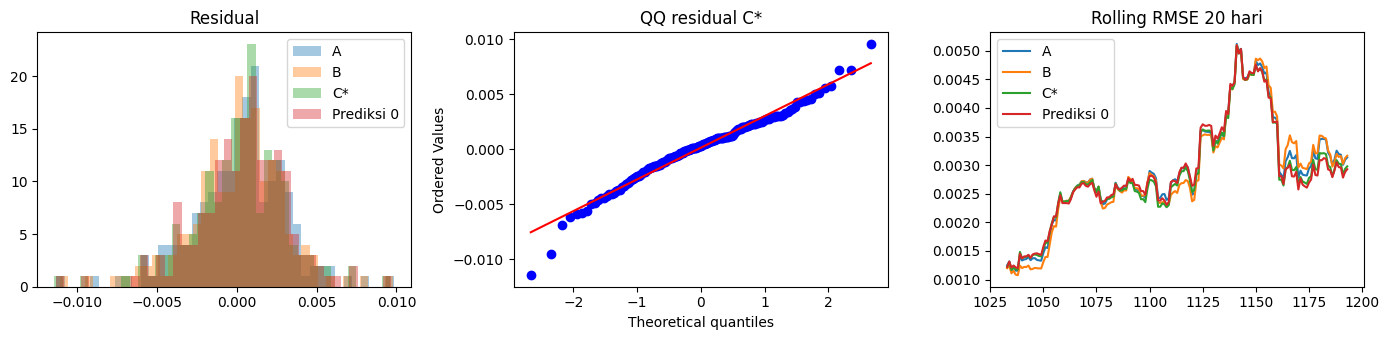

In [5]:
Pm = {"A": P[(bm, "A tuned")], "B": P[(bm, "B tuned")], "C*": P[(bm, "C* tuned")], "Prediksi 0": z}
E = pd.DataFrame({k: y.to_numpy() - v for k, v in Pm.items()}, index=te.index)
display(pd.DataFrame({"skew": E.skew(), "kurt": E.kurt(), "PredStd": {k: np.std(v) for k, v in Pm.items()}}).round(4))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for k in E: ax[0].hist(E[k], bins=40, alpha=.4, label=k)
ax[0].legend(); ax[0].set_title("Residual")
stats.probplot(E["C*"], plot=ax[1]); ax[1].set_title("QQ residual C*")
(E ** 2).rolling(20).mean().pow(.5).plot(ax=ax[2], title="Rolling RMSE 20 hari")
t3.show("error_dist")

,A,B,C*,Prediksi 0
RMSE per rezim volatilitas,,,,
rendah,0.002451,0.002385,0.002474,0.002506
sedang,0.002930,0.002975,0.002820,0.002786
tinggi,0.003523,0.003505,0.003440,0.003478


,A,B,C*,Prediksi 0
RMSE per berita,,,,
ada,0.002966,0.002958,0.002904,0.002918
tanpa,0.002497,0.002416,0.002539,0.002415


,A,B,C*,Prediksi 0
RMSE per news_count,,,,
0,0.002497,0.002416,0.002539,0.002415
1-2,0.001960,0.001856,0.001958,0.001947
3-5,0.002963,0.002986,0.002880,0.002856
>5,0.003219,0.003211,0.003158,0.003199


,A,B,C*,Prediksi 0
RMSE per |ret| target,,,,
kecil,0.000740,0.000804,0.000631,0.000648
sedang,0.001952,0.001923,0.001799,0.001811
besar,0.004675,0.004659,0.004640,0.004655


,A,B,C*
DirAcc per |ret|,,,
kecil,0.517,0.533,0.567
sedang,0.550,0.550,0.567
besar,0.567,0.550,0.567


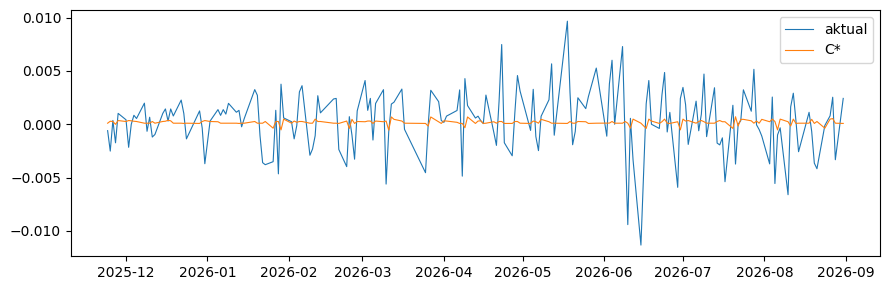

In [6]:
q = tr.ret_roll_std5.quantile([1 / 3, 2 / 3]).to_numpy()
groups = {"rezim volatilitas": pd.cut(te.ret_roll_std5, [-np.inf, *q, np.inf], labels=["rendah", "sedang", "tinggi"]),
          "berita": te.has_news.map({0: "tanpa", 1: "ada"}),
          "news_count": pd.cut(te.news_count, [-1, 0, 2, 5, np.inf], labels=["0", "1-2", "3-5", ">5"]),
          "|ret| target": pd.qcut(y.abs(), 3, labels=["kecil", "sedang", "besar"])}
for g, lab in groups.items():
    display(E.pow(2).groupby(lab, observed=True).mean().pow(.5).round(6).rename_axis(f"RMSE per {g}"))
display(pd.DataFrame({k: pd.Series(np.sign(v) == np.sign(y.to_numpy()), index=te.index).groupby(groups["|ret| target"], observed=True).mean()
                      for k, v in Pm.items() if k != "Prediksi 0"}).round(3).rename_axis("DirAcc per |ret|"))
plt.figure(figsize=(9, 3)); plt.plot(te.date, y, label="aktual", lw=.8); plt.plot(te.date, Pm["C*"], label="C*", lw=.8); plt.legend()
t3.show("pred_vs_actual")

## Feature importance

In [7]:
def coefs(est):
    pipe = (est.resid_ if hasattr(est, "resid_") else est).regressor_
    return pd.Series(pipe["model"].coef_, index=pipe["prep"].get_feature_names_out()).sort_values(key=abs, ascending=False) if hasattr(pipe["model"], "coef_") else None

for m, (s, f) in fin.items():
    c = coefs(R[(m, s, f)]["models"][0])
    if c is not None: display(c.head(10).round(4).rename(f"koefisien terstandardisasi | {m} C*"))

other = [t for t in CFG["emb_tags"] if t != sel["etag"]]
used = {b: c for b, c in blocks.items() if not any(b.endswith(t) for t in other)}
last = list(S["abl"].values())[-1]
tb = "finbert" if bs == "fb" else f"emb_{bs}"
for name, mods, bl in [("C*", R[(bm, bs, bf)]["models"], {"harga": PRICE, tb: blocks[tb]}), ("ablasi penuh", last["models"], used)]:
    imp = pd.concat([t3.block_importance(m, te, y, bl) for m in mods]).groupby(level=0)["naik_MSE"].agg(["mean", "std"]).sort_values("mean", ascending=False)
    display(imp.rename_axis(f"Grouped permutation importance (naik MSE) | {name}"))

num__ret_lag1         -0.0783
num__ret_lag0          0.0674
emb__pca2             -0.0536
emb__pca3             -0.0306
num__ret_lag3          0.0253
emb__pca0             -0.0234
num__ret_lag2          0.0163
emb__pca4              0.0135
num__ret_roll_mean5    0.0119
num__ret_lag4         -0.0031
Name: koefisien terstandardisasi | Ridge C*, dtype: float64

,mean,std
Grouped permutation importance (naik MSE) | C*,,
emb_bge_small,3.600132e-08,5.017926e-23
harga,-1.663475e-08,4.823250e-23


,mean,std
Grouped permutation importance (naik MSE) | ablasi penuh,,
emb_bge_small,1.653951e-08,0.000000e+00
F7_bge_small,7.132204e-09,9.760381e-23
F1,1.027183e-09,0.000000e+00
F2,4.409397e-10,9.778306e-23
F4,0.000000e+00,0.000000e+00
F3,0.000000e+00,0.000000e+00
F6,0.000000e+00,0.000000e+00
F5,0.000000e+00,0.000000e+00
F8,0.000000e+00,0.000000e+00
